<a href="https://colab.research.google.com/github/jessicalewinter/deep-learning-specialization/blob/main/mae5911/prova_1_codigo.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# MAE 5911 — Prova 1

## Aluna: Jessica Matias Lewinter

> **Aviso:** as respostas escritas da prova foram feitas à mão e estão entregues separadamente em outro arquivo.Neste documento coloquei só o código, os resultados que ele produz e uma explicação curta de cada passo.

Usei Python (NumPy, SciPy, statsmodels e PyTorch). Os dados são gerados aqui mesmo com
`np.random.default_rng`, usando as sementes do enunciado. Como o gerador do NumPy é diferente do gerador do R, as amostras não são numericamente iguais às que o código em R produziria.

In [2]:
import math
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels
import statsmodels.api as sm
import torch
import torch.nn.functional as F
from scipy.optimize import linprog, minimize
from scipy.stats import chi2, norm
from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.stats.diagnostic import acorr_ljungbox

torch.set_num_threads(1)
pd.set_option("display.float_format", lambda v: f"{v:.4f}")
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

print(
    f"numpy {np.__version__} | statsmodels {statsmodels.__version__} | torch {torch.__version__}"
)

numpy 2.4.6 | statsmodels 0.15.0 | torch 2.14.1+cpu


---
## Questão 1 — Regressão Bernoulli (2 pontos)

**Enunciado:**

> Gere os dados sem alterar a semente ou `n`:
>
> ```r
> set.seed(321)
> n = 80
> x1 = runif(n, -2, 2)
> x2 = runif(n, -2, 2)
> eta = 1 + 2 * x1 - 1.5 * x2
> p = plogis(eta)
> y = rbinom(n, size = 1, prob = p)
>
> dados_q1 = data.frame(y = y, x1 = x1, x2 = x2)
> ```
>
> Considere observações independentes, $x_i = (x_{1i}, x_{2i})$, $\theta = (\beta_0, \beta_1, \beta_2)$ e o modelo
>
> $$
> \begin{aligned}
> Y_i \mid X_{1i} = x_{1i},\, X_{2i} = x_{2i} &\sim \text{Bernoulli}\big(\mu_\theta(x_i)\big),\\
> \log\left[\frac{\mu_\theta(x_i)}{1-\mu_\theta(x_i)}\right] &= \beta_0 + \beta_1 x_{1i} + \beta_2 x_{2i}.
> \end{aligned}
> $$
>
> A função $\mu_\theta(x_i)$ representa a esperança condicional da resposta.
>
> Os três coeficientes são desconhecidos.
>
> Assuma que a distribuição das covariáveis não depende dos parâmetros.

In [3]:
# Gera a seed (set.seed(321)) com Numpy
rng = np.random.default_rng(321)
n = 80
x1 = rng.uniform(-2, 2, n)
x2 = rng.uniform(-2, 2, n)
eta = 1 + 2 * x1 - 1.5 * x2
p = 1 / (1 + np.exp(-eta))  # plogis(eta)
y = rng.binomial(1, p)
q1 = pd.DataFrame({"y": y, "x1": x1, "x2": x2})

X1 = np.column_stack(
    [np.ones(len(q1)), q1["x1"], q1["x2"]]
)  # linhas: x̃ᵢ = (1, x1ᵢ, x2ᵢ)
y1 = q1["y"].to_numpy(float)
print(q1.shape, "| proporção de y = 1:", y1.mean())
q1.head()

(80, 3) | proporção de y = 1: 0.6


,y,x1,x2
0,1,0.6351,-1.6551
1,1,1.6332,1.7863
2,0,-0.0662,1.1161
3,1,0.9016,-0.6521
4,0,0.2234,0.6129


### (a)

**Enunciado:**

> Obtenha a log-verossimilhança, as equações dos EMVs e suas estimativas. Apresente as
> condições de consistência.

Eu calculo o EMV com o meu Newton-Raphson e confiro com o `statsmodels.Logit`. O escore
praticamente nulo em $\hat\theta$ confirma que o método convergiu.

In [4]:
def loglik_logit(beta, X, y):
    eta = X @ beta
    return float(np.sum(y * eta - np.logaddexp(0.0, eta)))  # log(1+e^η) estável


def newton_logit(X, y, tol=1e-10, maxit=100):
    # Newton-Raphson para U(θ) = Xᵀ(y − μ) = 0; para quando passo e resíduo são pequenos.
    beta = np.zeros(X.shape[1])
    for it in range(1, maxit + 1):
        mu = 1.0 / (1.0 + np.exp(-(X @ beta)))
        U = X.T @ (y - mu)
        I_n = (X * (mu * (1 - mu))[:, None]).T @ X  # = −∂U/∂θᵀ
        passo = np.linalg.solve(I_n, U)
        beta = beta + passo
        if np.max(np.abs(passo)) < tol and np.max(np.abs(U)) < 1e-8:
            return beta, it
    raise RuntimeError("Newton-Raphson não convergiu (possível EMV não finito)")


beta_hat, iteracoes = newton_logit(X1, y1)
mu_hat = 1 / (1 + np.exp(-(X1 @ beta_hat)))
ajuste_sm = sm.Logit(y1, X1).fit(disp=0)

nomes = ["β0", "β1", "β2"]
print(f"Newton-Raphson convergiu em {iteracoes} iterações")
print(f"max |U(θ̂)| = {np.abs(X1.T @ (y1 - mu_hat)).max():.1e}  (escore nulo no EMV)")
print("ℓ(θ̂) =", round(loglik_logit(beta_hat, X1, y1), 6))
pd.DataFrame(
    {
        "valor gerador": [1, 2, -1.5],
        "EMV (Newton próprio)": beta_hat,
        "EMV (statsmodels)": ajuste_sm.params,
    },
    index=nomes,
)

Newton-Raphson convergiu em 9 iterações
max |U(θ̂)| = 1.5e-15  (escore nulo no EMV)
ℓ(θ̂) = -14.96477


,valor gerador,EMV (Newton próprio),EMV (statsmodels)
β0,1.0000,1.6665,1.6665
β1,2.0000,3.3488,3.3488
β2,-1.5000,-2.3793,-2.3793


### (b)

**Enunciado:**

> Construa e calcule o IC de Wald de 95% para $\beta_1$, usando a versão robusta discutida em
> sala. Interprete o nível de confiança.

Calculo a variância pelo estimador sanduíche $\hat I^{-1}(\sum_i\hat u_i\hat u_i^\top)\hat I^{-1}$, confiro
com o HC0 do `statsmodels` e monto o IC de 95% para $\beta_1$.

In [5]:
def cov_sanduiche(beta, X, y):
    mu = 1 / (1 + np.exp(-(X @ beta)))
    u = X * (y - mu)[:, None]
    I_hat = (X * (mu * (1 - mu))[:, None]).T @ X
    I_inv = np.linalg.inv(I_hat)
    return I_inv @ (u.T @ u) @ I_inv, I_inv


V_rob, V_mod = cov_sanduiche(beta_hat, X1, y1)
ep_rob, ep_mod = np.sqrt(np.diag(V_rob)), np.sqrt(np.diag(V_mod))
z975 = norm.ppf(0.975)
ic_b1 = (beta_hat[1] - z975 * ep_rob[1], beta_hat[1] + z975 * ep_rob[1])
ep_hc0_sm = sm.Logit(y1, X1).fit(disp=0, cov_type="HC0").bse

print(
    pd.DataFrame(
        {
            "EMV": beta_hat,
            "ep robusto (sanduíche)": ep_rob,
            "ep robusto (statsmodels HC0)": ep_hc0_sm,
            "ep modelo (Î⁻¹)": ep_mod,
        },
        index=nomes,
    ).to_string()
)
print(
    f"\nIC de Wald robusto de 95% para β1: [{ic_b1[0]:.4f}, {ic_b1[1]:.4f}]"
    f"   (β̂1 = {beta_hat[1]:.4f}, ep_rob = {ep_rob[1]:.4f})"
)

       EMV  ep robusto (sanduíche)  ep robusto (statsmodels HC0)  ep modelo (Î⁻¹)
β0  1.6665                  0.5192                        0.5192           0.6268
β1  3.3488                  0.9502                        0.9502           0.8295
β2 -2.3793                  0.8737                        0.8737           0.7954

IC de Wald robusto de 95% para β1: [1.4864, 5.2113]   (β̂1 = 3.3488, ep_rob = 0.9502)


### (c)

**Enunciado:**

> Para cada $n \in \{20, 100\}$, gere as covariáveis uma vez e mantenha-as fixas em 10 mil réplicas
> das respostas, com $(\beta_0, \beta_1, \beta_2) = (1, 2, -1.5)$. Tabule o viés empírico de $\beta_1$ e a cobertura do
> IC em (b) entre os ajustes com EMV finito, informando essa condicionalidade e a frequência
> de casos sem EMV finito. Compare a cobertura com 95%.

In [6]:
BETA_VERDADEIRO = np.array([1.0, 2.0, -1.5])
SEMENTE_COV = {20: 2101, 100: 2102}  # covariáveis fixas (geradas uma única vez)
SEMENTE_Q1C = {20: 1020, 100: 1100}  # réplicas de y
R_REPLICAS = 10_000


def tem_separacao(X, y):
    A = X * (2 * y - 1)[:, None]
    res = linprog(
        c=-A.sum(0),
        A_ub=-A,
        b_ub=np.zeros(len(y)),
        bounds=[(-1, 1)] * X.shape[1],
        method="highs",
    )
    return -res.fun > 1e-8


def newton_lote(X, Y, maxit=100, tol=1e-10):
    # Newton-Raphson
    B = np.zeros((Y.shape[0], X.shape[1]))
    conv = np.zeros(Y.shape[0], dtype=bool)
    for _ in range(maxit):
        P = 1 / (1 + np.exp(-(B @ X.T)))
        U = (Y - P) @ X
        H = np.einsum("ri,ij,ik->rjk", P * (1 - P), X, X)
        passo = np.linalg.solve(H, U[..., None])[..., 0]
        B = B + np.where(conv[:, None], 0.0, passo)
        conv |= (np.abs(passo).max(1) < tol) & (np.abs(U).max(1) < 1e-8)
        if conv.all():
            break
    return B, conv


def ep_sanduiche_lote(X, Y, B, j=1):
    P = 1 / (1 + np.exp(-(B @ X.T)))
    u = (Y - P)[:, :, None] * X[None]
    Lam = np.einsum("rij,rik->rjk", u, u)
    I_inv = np.linalg.inv(np.einsum("ri,ij,ik->rjk", P * (1 - P), X, X))
    return np.sqrt((I_inv @ Lam @ I_inv)[:, j, j]), np.sqrt(I_inv[:, j, j])


linhas, guardados = [], {}
for n, semente in SEMENTE_Q1C.items():
    rng_cov = np.random.default_rng(SEMENTE_COV[n])
    X = np.column_stack(
        [np.ones(n), rng_cov.uniform(-2, 2, n), rng_cov.uniform(-2, 2, n)]
    )
    p_verd = 1 / (1 + np.exp(-(X @ BETA_VERDADEIRO)))
    rng = np.random.default_rng(semente)
    Y = (rng.random((R_REPLICAS, n)) < p_verd).astype(float)

    separada = np.array([tem_separacao(X, yr) for yr in Y])
    B, conv = newton_lote(X, Y[~separada])
    assert conv.all(), "há réplica sem separação em que o Newton não convergiu"
    ep_r, ep_m = ep_sanduiche_lote(X, Y[~separada], B)
    b1 = B[:, 1]
    cobre_rob = (b1 - z975 * ep_r <= 2) & (2 <= b1 + z975 * ep_r)
    cobre_mod = (b1 - z975 * ep_m <= 2) & (2 <= b1 + z975 * ep_m)
    m = len(b1)
    linhas.append(
        {
            "n": n,
            "réplicas": R_REPLICAS,
            "sem EMV finito (%)": 100 * separada.mean(),
            "com EMV finito": m,
            "viés empírico de β̂1 | finito": b1.mean() - 2,
            "ep Monte Carlo do viés": b1.std(ddof=1) / np.sqrt(m),
            "mediana(β̂1) − 2 | finito": np.median(b1) - 2,
            "cobertura IC robusto (%) | finito": 100 * cobre_rob.mean(),
            "ep Monte Carlo da cobertura (p.p.)": 100
            * np.sqrt(cobre_rob.mean() * (1 - cobre_rob.mean()) / m),
            "cobertura IC modelo Î⁻¹ (%) | finito": 100 * cobre_mod.mean(),
            "máx |β̂1| | finito": np.abs(b1).max(),
        }
    )
    guardados[n] = {"X": X, "Y": Y, "separada": separada, "b1": b1}

tabela_q1c = pd.DataFrame(linhas).set_index("n").T
tabela_q1c

n,20,100
réplicas,10000.0000,10000.0000
sem EMV finito (%),7.5600,0.0000
com EMV finito,9244.0000,10000.0000
viés empírico de β̂1 | finito,1.2653,0.1622
ep Monte Carlo do viés,0.0350,0.0051
mediana(β̂1) − 2 | finito,0.4589,0.0864
cobertura IC robusto (%) | finito,90.1882,94.3300
ep Monte Carlo da cobertura (p.p.),0.3094,0.2313
cobertura IC modelo Î⁻¹ (%) | finito,97.7066,95.9900
máx |β̂1| | finito,51.5995,8.1924


Aqui ilustro um caso sem EMV finito: ao longo da direção separadora, a log-verossimilhança
cresce sem nunca atingir um máximo.

In [7]:
# Numa réplica separada (n = 20), ℓ cresce ao longo da direção separadora
# b* (solução do PL) e se aproxima do supremo sem atingi-lo, logo não há EMV finito.
g = guardados[20]
y_sep = g["Y"][g["separada"]][0]
A = g["X"] * (2 * y_sep - 1)[:, None]
b_sep = linprog(
    c=-A.sum(0), A_ub=-A, b_ub=np.zeros(20), bounds=[(-1, 1)] * 3, method="highs"
).x
print("direção separadora b* =", np.round(b_sep, 4))
for t in [0, 1, 10, 100, 1000]:
    print(f"  t = {t:>5}:  ℓ(t·b*) = {loglik_logit(t * b_sep, g['X'], y_sep):.6f}")
print(
    "supremo = −2·log 2 =",
    round(-2 * math.log(2), 6),
    "(2 observações empatadas na fronteira, separação quase completa)",
)

direção separadora b* = [-0.2934  1.     -0.678 ]
  t =     0:  ℓ(t·b*) = -13.862944
  t =     1:  ℓ(t·b*) = -7.419065
  t =    10:  ℓ(t·b*) = -1.680830
  t =   100:  ℓ(t·b*) = -1.386294
  t =  1000:  ℓ(t·b*) = -1.386294
supremo = −2·log 2 = -1.386294 (2 observações empatadas na fronteira: separação quase completa)


### (e)

**Enunciado:**

> Para este item, gere a amostra abaixo. Usando a rede neural vista em sala, ajuste redes
> Bernoulli com uma entrada, uma camada oculta de $N = 1, 5, 20$ e $100$ neurônios, ativação
> GELU, interceptos e saída logística $\mu_\theta(x)$. Use 80% para treino e 20% para teste. Antes de
> construir cada rede, fixe `torch_manual_seed(321)`; antes de cada chamada a `estimacao`,
> fixe `set.seed(2026)` para repetir a partição. Use Adam, taxa de aprendizado 0.01 e 20 mil
> épocas para todas as redes, ajustando os pesos somente no treino. Apresente apenas um
> gráfico das perdas médias finais de treino e teste (negativo da log-verossimilhança média)
> em função de $N$, que permita identificar subajuste, bom ajuste e sobreajuste.
>
> ```r
> set.seed(32)
> n = 200
> x = runif(n, -4, 4)
> f = function(x) 2*sin(3*x)+cos(5*x)
> p = function(x) plogis(f(x))
> y = rbinom(n, size = 1, prob = p(x))
> ```

In [10]:
# seed 32 com o gerador do NumPy
rng = np.random.default_rng(32)
n = 200
x = rng.uniform(-4, 4, n)
f = lambda x: 2 * np.sin(3 * x) + np.cos(5 * x)
y = rng.binomial(1, 1 / (1 + np.exp(-f(x))))
# partição 80/20 com semente 2026 — a mesma para as quatro redes
I_tr = np.random.default_rng(2026).choice(n, size=int(0.8 * n), replace=False)
q1e = pd.DataFrame({"y": y, "x": x, "treino": np.isin(np.arange(n), I_tr).astype(int)})

treino = q1e["treino"].to_numpy() == 1
para_tensor = lambda a: torch.tensor(np.asarray(a), dtype=torch.float32)[:, None]
x_tr, y_tr = para_tensor(q1e["x"][treino]), para_tensor(q1e["y"][treino])
x_te, y_te = para_tensor(q1e["x"][~treino]), para_tensor(q1e["y"][~treino])
print(f"treino: {treino.sum()} obs | teste: {(~treino).sum()} obs")


class RedeBernoulli(torch.nn.Module):
    def __init__(self, N):
        super().__init__()
        self.seq = torch.nn.Sequential(
            torch.nn.Linear(1, N), torch.nn.GELU(), torch.nn.Linear(N, 1)
        )

    def forward(self, x): # μ(x) = sigmoid(η(x))
        return self.seq(x)


def nll_media(rede, x, y):
    return F.binary_cross_entropy_with_logits(rede(x), y)


perdas = {}
for N in [1, 5, 20, 100]:
    torch.manual_seed(321)  # antes de construir cada rede
    rede = RedeBernoulli(N)
    otim = torch.optim.Adam(rede.parameters(), lr=0.01)
    t0 = time.time()
    for _ in range(20_000):
        L = nll_media(rede, x_tr, y_tr)
        otim.zero_grad()
        L.backward()
        otim.step()
    with torch.no_grad():
        perdas[N] = (
            nll_media(rede, x_tr, y_tr).item(),
            nll_media(rede, x_te, y_te).item(),
        )
    print(
        f"N = {N:>3}: treino = {perdas[N][0]:.4f} | teste = {perdas[N][1]:.4f}  ({time.time() - t0:.1f}s)"
    )

p_te = 1 / (
    1 + np.exp(-(2 * np.sin(3 * q1e["x"][~treino]) + np.cos(5 * q1e["x"][~treino])))
)
yte = q1e["y"][~treino].to_numpy()
ref_verdadeiro = -np.mean(yte * np.log(p_te) + (1 - yte) * np.log(1 - p_te))
pbar = y_tr.mean().item()
ref_constante = -np.mean(yte * np.log(pbar) + (1 - yte) * np.log(1 - pbar))

treino: 160 obs | teste: 40 obs
N =   1: treino = 0.6494 | teste = 0.6760  (30.9s)
N =   5: treino = 0.5103 | teste = 0.5877  (24.4s)
N =  20: treino = 0.3758 | teste = 0.5856  (21.0s)
N = 100: treino = 0.3716 | teste = 0.6053  (41.5s)


Faço um único gráfico com as perdas médias finais de treino e de teste em função de $N$.

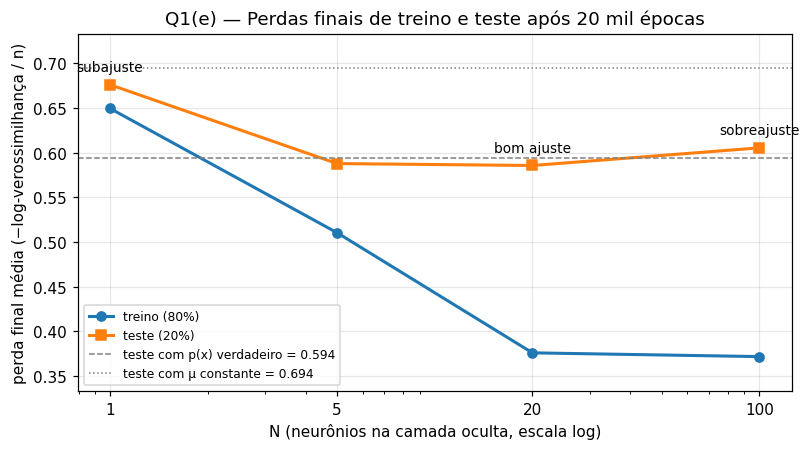

In [11]:
Ns = list(perdas)
fig, ax = plt.subplots(figsize=(7.5, 4.2))
ax.plot(Ns, [perdas[N][0] for N in Ns], "o-", lw=2, label="treino (80%)")
ax.plot(Ns, [perdas[N][1] for N in Ns], "s-", lw=2, label="teste (20%)")
ax.axhline(
    ref_verdadeiro,
    color="gray",
    ls="--",
    lw=1,
    label=f"teste com p(x) verdadeiro = {ref_verdadeiro:.3f}",
)
ax.axhline(
    ref_constante,
    color="gray",
    ls=":",
    lw=1,
    label=f"teste com μ constante = {ref_constante:.3f}",
)
ax.set_xscale("log")
ax.set_xticks(Ns, [str(N) for N in Ns])
N_bom = min(Ns, key=lambda N: perdas[N][1])  # menor perda de teste
for N, txt in [(1, "subajuste"), (N_bom, "bom ajuste"), (100, "sobreajuste")]:
    ax.annotate(
        txt,
        (N, perdas[N][1]),
        textcoords="offset points",
        xytext=(0, 9),
        ha="center",
        fontsize=9,
    )
ax.set(
    xlabel="N (neurônios na camada oculta, escala log)",
    ylabel="perda final média (−log-verossimilhança / n)",
    title="Q1(e) — Perdas finais de treino e teste após 20 mil épocas",
)
ax.margins(y=0.12)
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

## Análise
Com $N=1$ a rede subajusta: as perdas de treino e de teste são altas e
próximas entre si, quase no nível de um modelo constante. Com um único neurônio GELU a
função é quase monótona e não consegue acompanhar $f(x)=2\sin 3x+\cos 5x$, que oscila várias
vezes em $[-4,4]$.

Com $N=5$ e $N=20$ o ajuste é bom. A perda de teste cai para cerca de 0,588 nos dois casos, que é o nível da perda de teste calculada com o
$p(x)$ verdadeiro (0,594). Entre os dois, a perda de treino cai bastante sem
nenhum ganho no teste, o que sugere que $N=20$ já está no limite.

Com $N=100$ a rede sobreajusta. A perda de treino é a menor de todas (0,37), mas a de teste sobe para 0,61: o número de neurônios serve para ajustar particularidades do treino que não se repetem em dados novos.


---
## Questão 3 — Classificação multinomial (3 pontos)

**Enunciado:**

> Gere os dados sem alterar a semente ou `n`:
>
> ```r
> set.seed(123)
> n = 600
> x = runif(n, -3, 3)
>
> eta = cbind(0, 2 * sin(x), 1 - x^2)
> p = exp(eta)
> p = p / rowSums(p)
>
> y = vapply(
>   seq_len(n),
>   function(i) sample.int(3, 1, prob = p[i, ]),
>   integer(1)
> )
>
> dados = data.frame(x = x, y = factor(y, levels = 1:3))
> ```
>
> Para observações independentes, represente cada classe pelo vetor $Y = (Y_1, Y_2, Y_3)$, com $Y_j = 1$
> se a classe observada for $j$ e $Y_j = 0$ caso contrário. Modele o vetor de esperanças condicionais
> $\mu_\theta(x) = E_\theta(Y \mid X = x)$, que neste caso coincide com o vetor de probabilidades das classes, por
> uma rede com uma entrada, três neurônios na única camada oculta com ativação logística e três
> escores de saída. Inclua os interceptos nas duas camadas e use
>
> $$
> \mu_{j,\theta}(x) = \frac{\exp\big(z_{j,\theta}(x)\big)}{\sum_{k=1}^{3}\exp\big(z_{k,\theta}(x)\big)}, \qquad j = 1, 2, 3.
> $$
>
> Assuma que a distribuição das covariáveis não depende dos parâmetros.

### (b)

**Enunciado:**

> Ajuste a rede em R ou Python por maximização numérica da verossimilhança usando o
> AdamW com `weight_decay = 0` e com pelo menos cinco inicializações distintas. Use os mesmos hiperparâmetros (épocas, taxa de aprendizado, etc.). Compare as log-verossimilhanças
> finais e selecione o maior valor obtido.

In [13]:
# Bloco do enunciado (set.seed(123)) com o gerador do NumPy
rng = np.random.default_rng(123)
n = 600
x = rng.uniform(-3, 3, n)
eta = np.column_stack([np.zeros(n), 2 * np.sin(x), 1 - x**2])
p = np.exp(eta)
p = p / p.sum(1, keepdims=True)
y = np.array(
    [rng.choice(3, p=p[i]) + 1 for i in range(n)]
)  # sample.int(3, 1, prob = p[i, ])
q3 = pd.DataFrame({"x": x, "y": y})

x3 = torch.tensor(q3["x"].to_numpy(), dtype=torch.float32)[:, None]
c3 = torch.tensor(
    q3["y"].to_numpy() - 1
)  # classes 0, 1, 2 (índice da classe observada)
print("frequências das classes:", np.bincount(q3["y"])[1:])


class RedeMultinomial(torch.nn.Module):
    # 1 entrada -> 3 neurônios logísticos -> 3 escores (interceptos nas duas camadas)
    def __init__(self):
        super().__init__()
        self.oculta = torch.nn.Linear(1, 3)
        self.saida = torch.nn.Linear(3, 3)

    def forward(self, x):  # escores z_θ(x); μ_θ(x) = softmax(z_θ(x))
        return self.saida(torch.sigmoid(self.oculta(x)))


def menos_loglik(rede):  # −ℓ(θ) = Σᵢ [log Σₖ e^{zₖ} − z_{cᵢ}]
    return F.cross_entropy(rede(x3), c3, reduction="sum")


LR_Q3, EPOCAS_Q3, SEMENTES_Q3 = 0.05, 20_000, [1, 2, 3, 4, 5]
ajustes_q3 = {}
for s in SEMENTES_Q3:
    torch.manual_seed(s)
    rede = RedeMultinomial()
    l_inicial = -menos_loglik(rede).item()
    otim = torch.optim.AdamW(rede.parameters(), lr=LR_Q3, weight_decay=0.0)
    for _ in range(EPOCAS_Q3):
        L = menos_loglik(rede)
        otim.zero_grad()
        L.backward()
        otim.step()
    ajustes_q3[s] = (rede, l_inicial, -menos_loglik(rede).item())

tab_q3 = pd.DataFrame(
    {
        "ℓ inicial": [v[1] for v in ajustes_q3.values()],
        "ℓ final": [v[2] for v in ajustes_q3.values()],
    },
    index=pd.Index(SEMENTES_Q3, name="semente"),
)
s_melhor = tab_q3["ℓ final"].idxmax()
rede_q3 = ajustes_q3[s_melhor][0]
tab_q3["diferença para o máximo"] = tab_q3["ℓ final"] - tab_q3["ℓ final"].max()

eta_v = np.column_stack([np.zeros(len(q3)), 2 * np.sin(q3["x"]), 1 - q3["x"] ** 2])
p_v = np.exp(eta_v) / np.exp(eta_v).sum(1, keepdims=True)
l_gerador = np.log(p_v[np.arange(len(q3)), q3["y"] - 1]).sum()
print(tab_q3.to_string())
print(
    f"\nmaior log-verossimilhança: semente {s_melhor}, ℓ(θ̂) = {tab_q3['ℓ final'].max():.4f}"
)
print(f"referência: ℓ avaliada nas probabilidades geradoras p_j(x) = {l_gerador:.4f}")

frequências das classes: [227 261 112]
         ℓ inicial   ℓ final  diferença para o máximo
semente                                              
1        -654.6628 -430.7710                  -0.3389
2        -661.2317 -430.4379                  -0.0057
3        -696.6838 -430.6899                  -0.2578
4        -630.9307 -430.6451                  -0.2130
5        -647.4525 -430.4322                   0.0000

maior log-verossimilhança: semente 5, ℓ(θ̂) = -430.4322
referência: ℓ avaliada nas probabilidades geradoras p_j(x) = -436.0510


### (c)

**Enunciado:**

> Em três gráficos, compare as probabilidades estimadas $\mu_{j,\theta}(x)$ com as geradoras $p_j(x)$, $j =
> 1, 2, 3$, numa grade para a covariável em $[-3, 3]$. Para as geradoras, use $(p_1(x), p_2(x), p_3(x)) =
> \operatorname{softmax}(0, 2\sin(x), 1 - x^2)$, como no código acima.

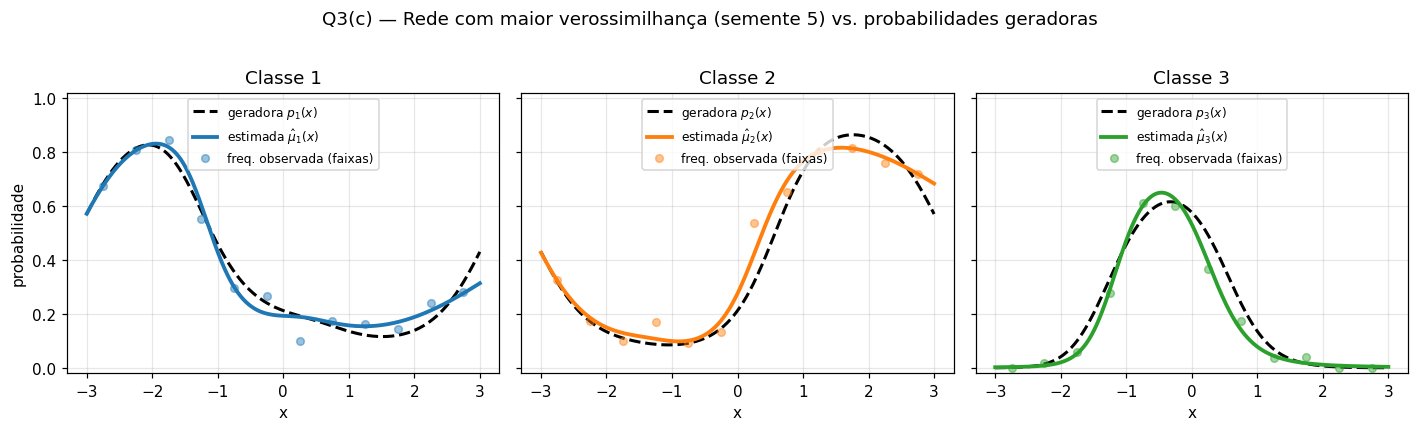

erro absoluto médio |μ̂_j − p_j| na grade: [0.0283 0.0362 0.0322] | máximo: [0.1163 0.1183 0.1225]


In [14]:
grade3 = np.linspace(-3, 3, 601)
with torch.no_grad():
    mu3 = torch.softmax(
        rede_q3(torch.tensor(grade3, dtype=torch.float32)[:, None]), dim=1
    ).numpy()
eta_g = np.column_stack([np.zeros_like(grade3), 2 * np.sin(grade3), 1 - grade3**2])
p3 = np.exp(eta_g) / np.exp(eta_g).sum(1, keepdims=True)

# frequências observadas por faixa de x (apenas visual)
faixas = np.linspace(-3, 3, 13)
centro = (faixas[:-1] + faixas[1:]) / 2
idx = np.clip(np.digitize(q3["x"], faixas) - 1, 0, 11)

fig, axs = plt.subplots(1, 3, figsize=(13, 3.8), sharey=True)
for j, ax in enumerate(axs):
    freq = [np.mean(q3["y"][idx == k] == j + 1) for k in range(12)]
    ax.plot(grade3, p3[:, j], "k--", lw=2, label=f"geradora $p_{j + 1}(x)$")
    ax.plot(
        grade3,
        mu3[:, j],
        color=f"C{j}",
        lw=2.5,
        label=rf"estimada $\hat\mu_{j + 1}(x)$",
    )
    ax.plot(
        centro,
        freq,
        "o",
        color=f"C{j}",
        alpha=0.45,
        ms=5,
        label="freq. observada (faixas)",
    )
    ax.set(title=f"Classe {j + 1}", xlabel="x", ylim=(-0.02, 1.02))
    ax.legend(fontsize=8, loc="upper center")
axs[0].set_ylabel("probabilidade")
fig.suptitle(
    f"Q3(c) — Rede com maior verossimilhança (semente {s_melhor}) vs. probabilidades geradoras",
    y=1.02,
)
plt.tight_layout()
plt.show()
print(
    "erro absoluto médio |μ̂_j − p_j| na grade:",
    np.round(np.abs(mu3 - p3).mean(0), 4),
    "| máximo:",
    np.round(np.abs(mu3 - p3).max(0), 4),
)

## Análise
A rede recupera bem a forma das três curvas. A classe 3 domina perto de $x=0$, onde $1-x^2$ é
máximo; a classe 2 domina com $x$ entre 1 e 3, onde $2\sin x$ é grande; e a classe 1 cresce na
borda negativa. As maiores diferenças aparecem nos extremos de $[-3,3]$, onde há poucos dados e
as probabilidades mudam rápido. Com apenas 3 neurônios logísticos, a rede aproxima as
transições por uma combinação de três sigmoides, o que limita a precisão em detalhes locais.

---
## Questão 4 — Redes autorregressivas (3 pontos)

**Enunciado:**

> Gere os dados sem alterar a semente ou `n`:
>
> ```r
> set.seed(456)
> n = 1000
> burn = 200
> N = n + burn + 3
> x1 = runif(N, -1, 1)
> x2 = runif(N, -1, 1)
> e = rnorm(N)
> f = function(x) 0.4*x[,1] - 0.2*x[,2] + 0.1*x[,3] + 0.6*sin(x[,4]) + 0.4*x[,5]
> f_sigma2 = function(x) exp(-0.5 + 0.2*tanh(x[,1]) - 0.15*tanh(x[,2]) +
>                            0.1*tanh(x[,3]) + 0.25*x[,4] - 0.2*x[,5])
> y = mu = sigma2 = numeric(N)
> for (t in 4:N) {
>   w = cbind(y[t-1], y[t-2], y[t-3], x1[t], x2[t])
>   mu[t] = f(w)
>   sigma2[t] = f_sigma2(w)
>   y[t] = mu[t] + sqrt(sigma2[t])*e[t]
> }
> I = (burn+4):N
> dados = data.frame(y = y[I], x1 = x1[I], x2 = x2[I])
> ```
>
> Nas linhas de `dados`, reindexadas de 1 a $n$, defina para $t = 4, \ldots, n$
>
> $$
> w_t = (y_{t-1}, y_{t-2}, y_{t-3}, x_{1t}, x_{2t}).
> $$
>
> As funções geradoras da média e da variância são `f` e `f_sigma2`, definidas no código acima. Elas
> recebem uma matriz com uma linha por instante e as cinco entradas na ordem de $w_t$.
>
> Suponha $Y_t$, dado o passado e as covariáveis, com distribuição $\text{Normal}\big(\mu_\theta(w_t), \sigma^2_\theta(w_t)\big)$. As
> covariáveis são observadas antes de $Y_t$.
>
> Use duas redes com cinco entradas, dez neurônios na única camada oculta (ativação GELU),
> interceptos e uma saída: uma para $\mu_\theta$ e outra para $\log(\sigma^2_\theta)$.
>
> Assuma que a distribuição das covariáveis não depende dos parâmetros.
>
> Assuma também que a distribuição dos três primeiros valores observados, dados os valores das
> covariáveis, não depende dos parâmetros.

### (b)

**Enunciado:**

> Ajuste conjuntamente as redes em R ou Python, minimizando o negativo da log-verossimilhança para $t = 4, \ldots, 800$. Informe o otimizador e o critério de parada.
> Utilize as funções geradoras `f` e `f_sigma2` apenas na geração dos dados e nas comparações
> gráficas.

In [15]:
# Bloco do enunciado (set.seed(456)) com o gerador do NumPy
def f_ger(w):  # f do enunciado: usada SOMENTE na geração e nas comparações gráficas
    return (
        0.4 * w[:, 0]
        - 0.2 * w[:, 1]
        + 0.1 * w[:, 2]
        + 0.6 * np.sin(w[:, 3])
        + 0.4 * w[:, 4]
    )


def f_sigma2_ger(w):  # f_sigma2 do enunciado
    return np.exp(
        -0.5
        + 0.2 * np.tanh(w[:, 0])
        - 0.15 * np.tanh(w[:, 1])
        + 0.1 * np.tanh(w[:, 2])
        + 0.25 * w[:, 3]
        - 0.2 * w[:, 4]
    )


rng = np.random.default_rng(456)
n, burn = 1000, 200
N = n + burn + 3
x1 = rng.uniform(-1, 1, N)
x2 = rng.uniform(-1, 1, N)
e = rng.normal(size=N)
y = np.zeros(N)
for t in range(3, N):  # t = 4..N no R
    w = np.array([[y[t - 1], y[t - 2], y[t - 3], x1[t], x2[t]]])
    y[t] = f_ger(w)[0] + np.sqrt(f_sigma2_ger(w)[0]) * e[t]
I = slice(burn + 3, N)  # I = (burn+4):N
q4 = pd.DataFrame({"y": y[I], "x1": x1[I], "x2": x2[I]})

yq, x1q, x2q = (q4[c].to_numpy() for c in ["y", "x1", "x2"])
n4 = len(q4)
t_idx = np.arange(4, n4 + 1)  # t = 4..n (indexação 1-based do enunciado)
W4 = np.column_stack(
    [yq[t_idx - 2], yq[t_idx - 3], yq[t_idx - 4], x1q[t_idx - 1], x2q[t_idx - 1]]
)  # w_t
Y4 = yq[t_idx - 1]  # y_t
TR, TE = t_idx <= 800, t_idx >= 801
FIT, VAL = t_idx <= 640, (t_idx >= 641) & (t_idx <= 800)
print(
    f"w_t para t = 4..{n4}: {len(t_idx)} linhas | treino t≤800: {TR.sum()} | teste t≥801: {TE.sum()}"
)

dt = torch.float64
Wt, Yt = torch.tensor(W4, dtype=dt), torch.tensor(Y4, dtype=dt)[:, None]


def nova_rede():  # 5 entradas -> 10 GELU -> 1 saída, com interceptos
    return torch.nn.Sequential(
        torch.nn.Linear(5, 10), torch.nn.GELU(), torch.nn.Linear(10, 1)
    ).to(dt)


def nll_normal(rede_mu, rede_ls, mascara):  # −ℓ média (inclui a constante ½log 2π)
    mu, log_s2 = rede_mu(Wt[mascara]), rede_ls(Wt[mascara])
    return torch.mean(
        0.5 * math.log(2 * math.pi)
        + 0.5 * log_s2
        + (Yt[mascara] - mu) ** 2 / (2 * torch.exp(log_s2))
    )


def treina(
    mascara,
    epocas=None,
    mascara_val=None,
    lr=1e-3,
    paciencia=300,
    min_delta=1e-6,
    max_epocas=20_000,
):
    torch.manual_seed(456)
    rede_mu, rede_ls = nova_rede(), nova_rede()
    otim = torch.optim.Adam(
        list(rede_mu.parameters()) + list(rede_ls.parameters()), lr=lr
    )
    hist, melhor = [], (np.inf, 0)
    for ep in range(1, (epocas or max_epocas) + 1):
        L = nll_normal(rede_mu, rede_ls, mascara)
        otim.zero_grad()
        L.backward()
        otim.step()
        if mascara_val is not None:
            with torch.no_grad():
                v = nll_normal(rede_mu, rede_ls, mascara_val).item()
            hist.append((L.item(), v))
            if v < melhor[0] - min_delta:
                melhor = (v, ep)
            elif ep - melhor[1] >= paciencia:
                break
    return rede_mu, rede_ls, melhor, hist


# Passo 1: escolher E* por validação interna (t = 641..800)
_, _, (nll_val, E_estrela), hist_val = treina(FIT, mascara_val=VAL)
# Passo 2: ajuste final em t = 4..800 por E* épocas
rede_mu, rede_ls, _, _ = treina(TR, epocas=E_estrela)
with torch.no_grad():
    nll_tr_final = nll_normal(rede_mu, rede_ls, TR).item()
print(
    f"E* = {E_estrela} épocas (NLL média de validação = {nll_val:.4f}; parada na época {len(hist_val)})"
)
print(f"ajuste final em t = 4..800: NLL média de treino = {nll_tr_final:.4f}")

w_t para t = 4..1000: 997 linhas | treino t≤800: 797 | teste t≥801: 200
E* = 183 épocas (NLL média de validação = 1.1613; parada na época 483)
ajuste final em t = 4..800: NLL média de treino = 1.1402


Este é o diagnóstico do critério de parada, sem parar cedo, a variância degenera e a NLL de
validação piora.

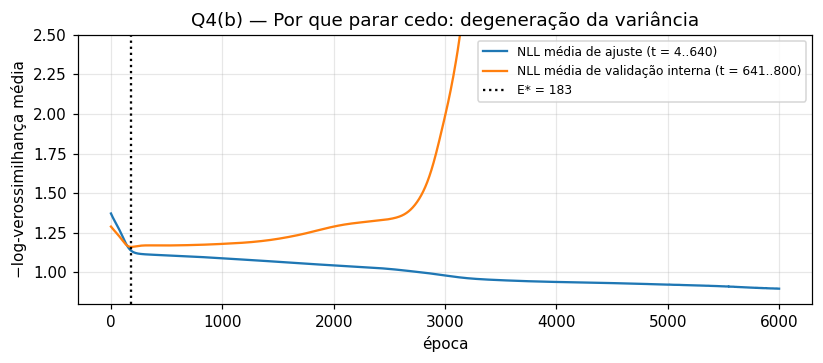

sem parada (6 mil épocas): NLL de ajuste 0.898 (continua caindo) e de validação 21.070 (piora; eixo y cortado em 2,5 no gráfico)


In [16]:
# Diagnóstico do critério de parada: o mesmo ajuste levado a 6 mil épocas sem parar.
_, _, _, hist_longo = treina(FIT, epocas=6000, mascara_val=VAL, paciencia=10**9)
h = np.array(hist_longo)
fig, ax = plt.subplots(figsize=(7.5, 3.4))
ax.plot(h[:, 0], label="NLL média de ajuste (t = 4..640)")
ax.plot(h[:, 1], label="NLL média de validação interna (t = 641..800)")
ax.axvline(E_estrela, color="k", ls=":", label=f"E* = {E_estrela}")
ax.set(
    xlabel="época",
    ylabel="−log-verossimilhança média",
    ylim=(0.8, 2.5),
    title="Q4(b) — Por que parar cedo: degeneração da variância",
)
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()
print(
    f"sem parada (6 mil épocas): NLL de ajuste {h[-1, 0]:.3f} (continua caindo) e de validação"
    f" {h[-1, 1]:.3f} (piora; eixo y cortado em 2,5 no gráfico)"
)

## Análise
O gráfico justifica o critério. Depois de algumas centenas de épocas, a NLL de ajuste continua
caindo, porque a rede de $\log\sigma^2$ começa a encolher a variância em pontos específicos do
treino, enquanto a NLL de validação, calculada em dados que a rede não viu, só piora. A parada
em $E^*$ acontece no platô de menor NLL de validação, antes dessa degeneração.

### (c)

**Enunciado:**

> Sem reajustar no teste, faça previsões de um passo para $t = 801, \ldots, 1000$, usando o passado
> observado. Compare em gráficos as médias $\mu_\theta(w_t)$ e as variâncias $\sigma^2_\theta(w_t)$ estimadas com as
> geradoras `f`$(w_t)$ e `f_sigma2`$(w_t)$, respectivamente. Examine os resíduos padronizados e sua
> autocorrelação.

Faço a previsão de um passo em $t=801,\dots,1000$ com os pesos congelados e comparo
$\hat\mu_\theta(w_t)$ com $f(w_t)$ e $\hat\sigma^2_\theta(w_t)$ com $f_{\sigma^2}(w_t)$.

NLL média de teste: rede = 1.2025 | com f e f_sigma2 verdadeiras = 1.1754
média:     corr(μ̂, f) = 0.979 | REQM(μ̂ − f) = 0.1357
variância: corr(σ̂², f_σ²) = 0.736 | REQM(σ̂² − f_σ²) = 0.1255
resíduos padronizados: média = -0.103, dp = 1.054


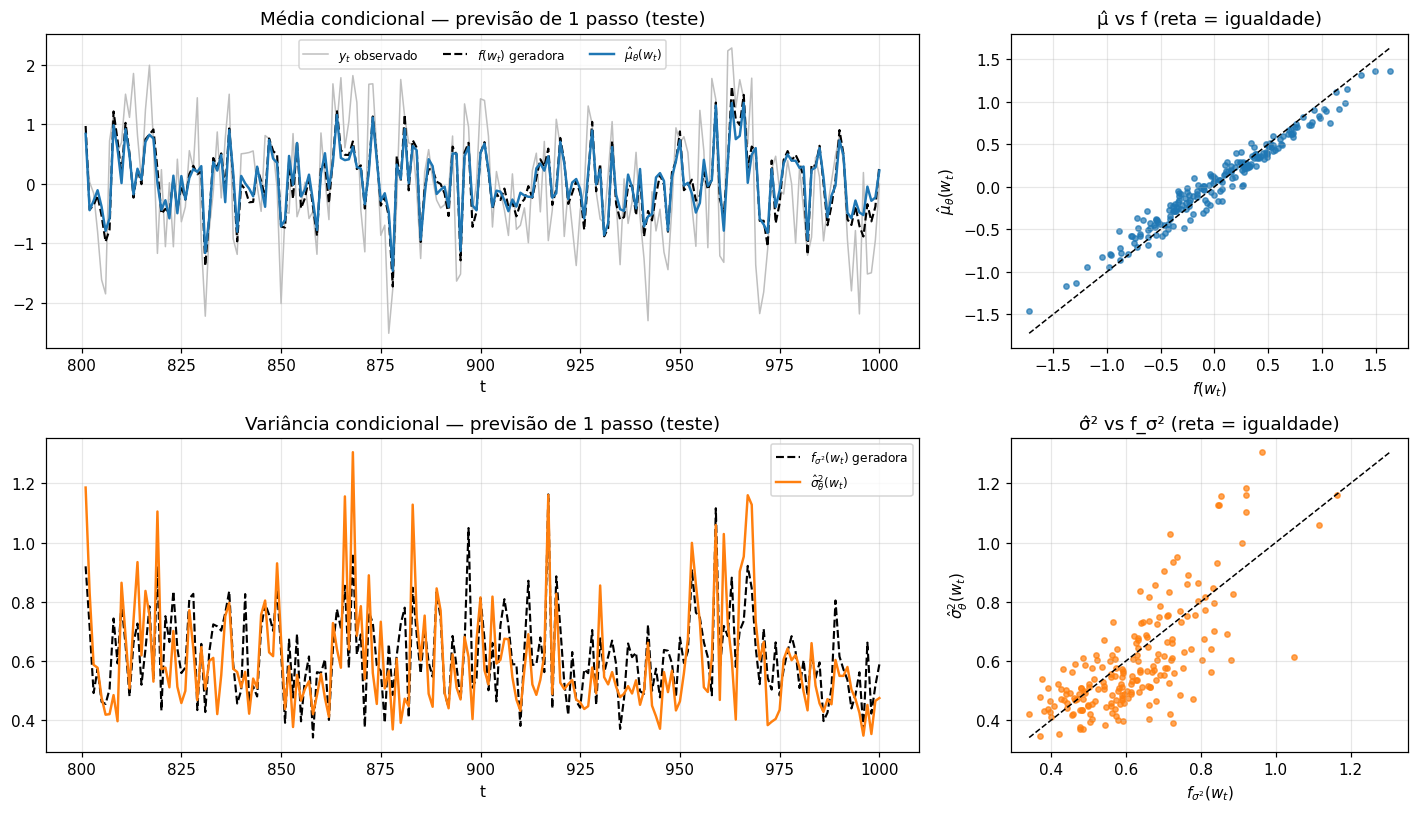

In [17]:
with torch.no_grad():  # previsão de 1 passo com pesos congelados
    mu_te = rede_mu(Wt[TE]).numpy().ravel()
    s2_te = np.exp(rede_ls(Wt[TE]).numpy().ravel())
    nll_te = nll_normal(rede_mu, rede_ls, TE).item()
w_te, y_te4, t_te = W4[TE], Y4[TE], t_idx[TE]
f_te, fs2_te = f_ger(w_te), f_sigma2_ger(w_te)
residuo = (y_te4 - mu_te) / np.sqrt(s2_te)
nll_ger_te = np.mean(
    0.5 * np.log(2 * np.pi * fs2_te) + (y_te4 - f_te) ** 2 / (2 * fs2_te)
)

print(
    f"NLL média de teste: rede = {nll_te:.4f} | com f e f_sigma2 verdadeiras = {nll_ger_te:.4f}"
)
print(
    f"média:     corr(μ̂, f) = {np.corrcoef(mu_te, f_te)[0, 1]:.3f} | REQM(μ̂ − f) = {np.sqrt(np.mean((mu_te - f_te) ** 2)):.4f}"
)
print(
    f"variância: corr(σ̂², f_σ²) = {np.corrcoef(s2_te, fs2_te)[0, 1]:.3f} | REQM(σ̂² − f_σ²) = {np.sqrt(np.mean((s2_te - fs2_te) ** 2)):.4f}"
)
print(
    f"resíduos padronizados: média = {residuo.mean():.3f}, dp = {residuo.std(ddof=1):.3f}"
)

fig, axs = plt.subplots(2, 2, figsize=(13, 7.5), gridspec_kw={"width_ratios": [2.2, 1]})
axs[0, 0].plot(t_te, y_te4, color="0.75", lw=1, label="$y_t$ observado")
axs[0, 0].plot(t_te, f_te, "k--", lw=1.4, label="$f(w_t)$ geradora")
axs[0, 0].plot(t_te, mu_te, color="C0", lw=1.6, label=r"$\hat\mu_\theta(w_t)$")
axs[0, 0].set(title="Média condicional — previsão de 1 passo (teste)", xlabel="t")
axs[0, 0].legend(fontsize=8, ncol=3)
axs[0, 1].scatter(f_te, mu_te, s=12, alpha=0.7)
lim = [min(f_te.min(), mu_te.min()), max(f_te.max(), mu_te.max())]
axs[0, 1].plot(lim, lim, "k--", lw=1)
axs[0, 1].set(
    xlabel="$f(w_t)$",
    ylabel=r"$\hat\mu_\theta(w_t)$",
    title="μ̂ vs f (reta = igualdade)",
)
axs[1, 0].plot(t_te, fs2_te, "k--", lw=1.4, label=r"$f_{\sigma^2}(w_t)$ geradora")
axs[1, 0].plot(t_te, s2_te, color="C1", lw=1.6, label=r"$\hat\sigma^2_\theta(w_t)$")
axs[1, 0].set(title="Variância condicional — previsão de 1 passo (teste)", xlabel="t")
axs[1, 0].legend(fontsize=8)
axs[1, 1].scatter(fs2_te, s2_te, s=12, alpha=0.7, color="C1")
lim = [min(fs2_te.min(), s2_te.min()), max(fs2_te.max(), s2_te.max())]
axs[1, 1].plot(lim, lim, "k--", lw=1)
axs[1, 1].set(
    xlabel=r"$f_{\sigma^2}(w_t)$",
    ylabel=r"$\hat\sigma^2_\theta(w_t)$",
    title="σ̂² vs f_σ² (reta = igualdade)",
)
plt.tight_layout()
plt.show()

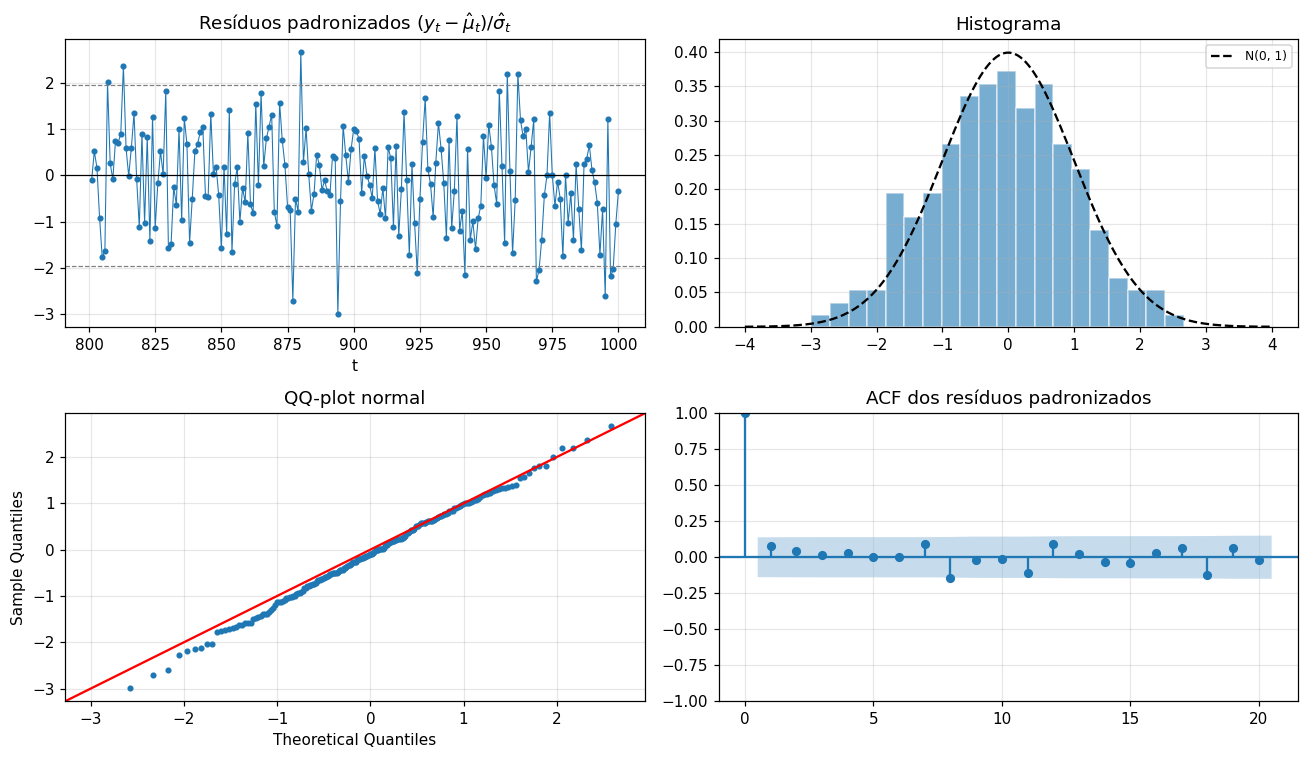

proporção de |resíduo| ≤ 1,96: 0.930 (esperado ≈ 0,95)
Ljung-Box (resíduos):
     lb_stat  lb_pvalue
5    1.8375     0.8711
10   7.7998     0.6484
20  18.3853     0.5620
Ljung-Box (resíduos²):
     lb_stat  lb_pvalue
5    3.5463     0.6164
10   6.5323     0.7687
20  19.2919     0.5029


In [18]:
fig, axs = plt.subplots(2, 2, figsize=(12, 7))
axs[0, 0].plot(t_te, residuo, "o-", ms=3, lw=0.7)
axs[0, 0].axhline(0, color="k", lw=0.8)
for k in (-1.96, 1.96):
    axs[0, 0].axhline(k, color="gray", ls="--", lw=0.8)
axs[0, 0].set(title=r"Resíduos padronizados $(y_t-\hat\mu_t)/\hat\sigma_t$", xlabel="t")
axs[0, 1].hist(residuo, bins=20, density=True, alpha=0.6, edgecolor="w")
gz = np.linspace(-4, 4, 200)
axs[0, 1].plot(gz, norm.pdf(gz), "k--", label="N(0, 1)")
axs[0, 1].set(title="Histograma")
axs[0, 1].legend(fontsize=8)
sm.qqplot(residuo, line="45", ax=axs[1, 0], markersize=3)
axs[1, 0].set_title("QQ-plot normal")
plot_acf(residuo, lags=20, ax=axs[1, 1], title="ACF dos resíduos padronizados")
plt.tight_layout()
plt.show()

lb = acorr_ljungbox(residuo, lags=[5, 10, 20])
lb2 = acorr_ljungbox(residuo**2, lags=[5, 10, 20])
dentro_95 = np.mean(np.abs(residuo) <= 1.96)
print(f"proporção de |resíduo| ≤ 1,96: {dentro_95:.3f} (esperado ≈ 0,95)")
print("Ljung-Box (resíduos):\n", lb.round(4).to_string())
print("Ljung-Box (resíduos²):\n", lb2.round(4).to_string())

## Análise
A média estimada $\hat\mu_\theta(w_t)$ acompanha de perto a geradora $f(w_t)$ no teste, com correlação
de cerca de 0,98 e os pontos em volta da reta de igualdade. A rede aprendeu tanto a parte linear
quanto o termo $0{,}6\sin(x_{1t})$ só a partir dos dados.

A variância estimada $\hat\sigma^2_\theta(w_t)$ segue o padrão de $f_{\sigma^2}(w_t)$, com correlação de
cerca de 0,74 e os picos principais nos mesmos instantes. Ela é bem mais ruidosa que a média e,
na faixa intermediária, tende a subestimar a variância (há mais pontos abaixo da reta). Isso
era de se esperar, porque a variância só é observada através de $(y_t-\mu_t)^2$, que varia muito
mais, e porque a parada antecipada deixa a rede de $\log\sigma^2$ relativamente pouco ajustada.

Os resíduos padronizados têm média de cerca de −0,10 e desvio-padrão de 1,05, e o histograma e o
QQ-plot ficam próximos da normal, com o QQ-plot um pouco deslocado para baixo. 93% dos resíduos
ficam dentro de ±1,96, contra os 95% esperados, o que é coerente com o desvio-padrão um pouco
acima de 1 e com a subestimação de $\sigma^2$ que comentei. A ACF fica dentro das bandas, e os
testes de Ljung-Box não rejeitam a ausência de autocorrelação nem nos resíduos nem nos seus
quadrados. Concluo que o modelo capturou a dinâmica da média (as três defasagens) e a
heterocedasticidade condicional. A NLL de teste (1,203) fica próxima da que se obtém com as
funções verdadeiras (1,175).